In [3]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
events =pd.read_excel('NHL-playoffs-2026.xlsx')
print(events.shape)
print(events.columns.tolist())

(29710, 39)
['Unnamed: 0', 'Dataset', 'Game ID', 'Date', 'Away Team', 'Home Team', 'Cumulated Away Score', 'Cumulated Home Score', 'Period', 'Elapsed Time', 'Remaining Time', 'Play ID', 'Play Length', 'Play Type', 'Play Subtype', 'Play Zone', 'Team Making the Play', 'Player in the Event #1', 'Player in the Event #2', 'Player in the Event #3', 'X Coordinate on the Ice Rink', 'Y Coordinate on the Ice Rink', "# of Away Team's Players on the Ice", "# of Home Team's Players on the Ice", "Away Team's Player on the Ice #1", "Away Team's Player on the Ice #2", "Away Team's Player on the Ice #3", "Away Team's Player on the Ice #4", "Away Team's Player on the Ice #5", "Away Team's Player on the Ice #6", "Away Team's Goalie", "Home Team's Player on the Ice #1", "Home Team's Player on the Ice #2", "Home Team's Player on the Ice #3", "Home Team's Player on the Ice #4", "Home Team's Player on the Ice #5", "Home Team's Player on the Ice #6", "Home Team's Goalie", "Home Team's Defending Side"]


In [ ]:
events =events.drop(columns=['Unnamed: 0'])

In [11]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


In [12]:
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 29710 entries, 0 to 29709
Data columns (total 38 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Dataset                              29710 non-null  str    
 1   Game ID                              29710 non-null  int64  
 2   Date                                 29710 non-null  str    
 3   Away Team                            29710 non-null  str    
 4   Home Team                            29710 non-null  str    
 5   Cumulated Away Score                 29710 non-null  int64  
 6   Cumulated Home Score                 29710 non-null  int64  
 7   Period                               29710 non-null  int64  
 8   Elapsed Time                         29710 non-null  str    
 9   Remaining Time                       29710 non-null  str    
 10  Play ID                              29710 non-null  int64  
 11  Play Length                          29

In [13]:
events['Game ID'].nunique()

82

In [14]:
events.groupby('Game ID').size()

Game ID
2025030111    376
2025030112    401
2025030113    328
2025030114    359
2025030115    392
             ... 
2025030412    360
2025030413    528
2025030414    327
2025030415    340
2025030416    343
Length: 82, dtype: int64

In [15]:
games=events.groupby('Game ID').agg({
    'Date': 'first',
    'Away Team': 'first',
    'Home Team': 'first',
    'Cumulated Away Score': 'max',
    'Cumulated Home Score': 'max',
    'Period': 'max'})
games.head()

,Date,Away Team,Home Team,Cumulated Away Score,Cumulated Home Score,Period
Game ID,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,3
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,3
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,3
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,3
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,4


In [16]:
games =games.rename(columns={
    'Cumulated Away Score': 'Away Score',
    'Cumulated Home Score': 'Home Score',
    'Period': 'Last Period'})
games.tail()

,Date,Away Team,Home Team,Away Score,Home Score,Last Period
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,4
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,5
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,3
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,3
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,3


In [18]:
games['Last Period'].value_counts().sort_index()

Last Period
3    60
4    18
5     4
Name: count, dtype: int64

In [19]:
games['Outcome'] = 'Final'
games.loc[games['Last Period'] == 4, 'Outcome'] = 'Final/OT'
games.loc[games['Last Period'] == 5, 'Outcome'] = 'Final/2OT'

In [20]:
games.head(10)

,Date,Away Team,Home Team,Away Score,Home Score,Last Period,Outcome
Game ID,,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,3,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,3,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,3,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,3,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,4,Final/OT
2025030116,2026-05-01,Buffalo Sabres,Boston Bruins,4,1,3,Final
2025030121,2026-04-19,Montréal Canadiens,Tampa Bay Lightning,4,3,4,Final/OT
2025030122,2026-04-21,Montréal Canadiens,Tampa Bay Lightning,2,3,4,Final/OT
2025030123,2026-04-24,Tampa Bay Lightning,Montréal Canadiens,2,3,4,Final/OT


In [21]:
games = games.drop(columns=['Last Period'])
games.tail()

,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


Итог задания2:

Из таблицы с 29710 записями получилась таблица games: в ней информация о 82 матчах.
Строки сгруппированы по столбцу "Game ID", в итоговую таблицу выведены столбцы с датой, командами, итоговый счёт (в 2 столбцах) и количество сыгранных периодов. После чего на основании количества периодов построен столбец "Outcome" - когда закончилась игра: в основное время, или сколько дополнительных периодов сыграно:
60 матчей закончились в основное время
18 матчей с одним овертаймом
4 матча с 2 овертаймами.

In [29]:
def gameInfo(gameId):
    game = games.loc[gameId]
    result = (f"{game['Home Team']} : {game['Away Team']} ({game['Home Score']} - {game['Away Score']}, "
            f"{game['Outcome']}, {game['Date']})")
    return result

In [30]:
print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres : Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights : Carolina Hurricanes (0 - 3, Final, 2026-06-14)


In [31]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

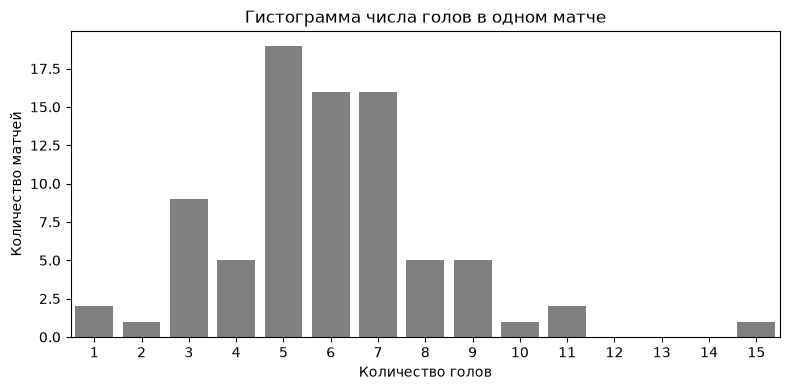

In [34]:
plt.figure(figsize=(8, 4))

sns.countplot(
    data=games,
    x='Total Score',
    order=range(1, 16),
    color='gray'

)

plt.xlabel('Количество голов')
plt.ylabel('Количество матчей')
plt.title('Гистограмма числа голов в одном матче')
plt.tight_layout()

plt.show()

#4-5. Результаты матчей

Результат матча - сумма двух столбцов'Away Score' и 'Home Score' - сумма голов двух команд за матч. 
За 82 игры в среднем было забито 5,93 шайбы за игру, медиана 6 шайб. Стандартное отклонение 2,26 шайбы.
Минимальное количество голов - 1, максимальное - 15. 
Выраженного смещения центральной части распределения нет - медиана и среднее близки. Но есть длинный хвост - матчи с 15 голами.

In [35]:
games['Total Score'].min(), games['Total Score'].max()

(np.int64(1), np.int64(15))

In [38]:
min_games = games[games['Total Score'] == games['Total Score'].min()]
max_games = games[games['Total Score'] == games['Total Score'].max()]

In [43]:
print("Игры с минимальным счетом")
[gameInfo(game_id) for game_id in min_games.index]


Игры с минимальным счетом


['Montréal Canadiens : Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers : Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [44]:
print("Игры с максимальным счетом")
[gameInfo(game_id) for game_id in max_games.index]

Игры с максимальным счетом


['Colorado Avalanche : Minnesota Wild (9 - 6, Final, 2026-05-03)']

In [46]:
away = [col for col in events.columns
             if col.startswith("Away Team's Player on the Ice #")]

home = [col for col in events.columns
             if col.startswith("Home Team's Player on the Ice #")]

away.append("Away Team's Goalie")
home.append("Home Team's Goalie")

print(away)
print(home)

["Away Team's Player on the Ice #1", "Away Team's Player on the Ice #2", "Away Team's Player on the Ice #3", "Away Team's Player on the Ice #4", "Away Team's Player on the Ice #5", "Away Team's Player on the Ice #6", "Away Team's Goalie"]
["Home Team's Player on the Ice #1", "Home Team's Player on the Ice #2", "Home Team's Player on the Ice #3", "Home Team's Player on the Ice #4", "Home Team's Player on the Ice #5", "Home Team's Player on the Ice #6", "Home Team's Goalie"]


In [51]:
player_counts =[]

for game_id in games.index:
    match = events[events['Game ID'] ==game_id]
    away_players = match[away].stack().nunique()
    home_players =  match[home].stack().nunique()
    player_counts.append(away_players + home_players)

games['Player Count']= player_counts

In [53]:
games['Game Info'] = [gameInfo(game_id) for game_id in games.index]
games.loc[games['Player Count'] == games['Player Count'].max(),
    ['Game Info', 'Player Count']]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens : Buffalo Sabres (3 - 8, Fi...",40


Для каждого матча рассчитано суммарноее количество уникальных игроков обеих команд.

Наибольшее количество уникальных участников зафиксировано в матче Montréal Canadiens : Buffalo Sabres (3:8). В нём приняли участие 40 игроков по 20 от каждой команды.

In [62]:
shot = events[events['Play Type'].isin(
    ['shot-on-goal', 'goal', 'missed-shot'])].copy()

shot.shape

(7266, 38)

In [63]:
shot[[
    'Game ID',
    'Play Type',
    'Team Making the Play',
    'Home Team',
    "Home Team's Defending Side",
    'X Coordinate on the Ice Rink',
    'Y Coordinate on the Ice Rink']].head(10)

,Game ID,Play Type,Team Making the Play,Home Team,Home Team's Defending Side,X Coordinate on the Ice Rink,Y Coordinate on the Ice Rink
7,2025030111,missed-shot,Buffalo Sabres,Buffalo Sabres,left,82.0,-13.0
9,2025030111,missed-shot,Boston Bruins,Buffalo Sabres,left,-77.0,2.0
12,2025030111,missed-shot,Buffalo Sabres,Buffalo Sabres,left,65.0,20.0
13,2025030111,shot-on-goal,Buffalo Sabres,Buffalo Sabres,left,28.0,15.0
19,2025030111,missed-shot,Buffalo Sabres,Buffalo Sabres,left,40.0,-23.0
23,2025030111,shot-on-goal,Boston Bruins,Buffalo Sabres,left,-71.0,-40.0
24,2025030111,shot-on-goal,Boston Bruins,Buffalo Sabres,left,-87.0,-4.0
28,2025030111,missed-shot,Buffalo Sabres,Buffalo Sabres,left,58.0,26.0
37,2025030111,missed-shot,Boston Bruins,Buffalo Sabres,left,-31.0,9.0
43,2025030111,missed-shot,Boston Bruins,Buffalo Sabres,left,-61.0,34.0


In [64]:
home_shot = shot['Team Making the Play'] == shot['Home Team']
away_shot = shot['Team Making the Play'] == shot['Away Team']

left =shot["Home Team's Defending Side"] =='left'
right = shot["Home Team's Defending Side"] == 'right'

shot['Goal X'] = np.nan

shot.loc[home_shot & left, 'Goal X'] = 89
shot.loc[away_shot & left, 'Goal X'] = -89
shot.loc[home_shot & right, 'Goal X'] = -89
shot.loc[away_shot & right, 'Goal X'] = 89

In [65]:
shot[[
    'Team Making the Play',
    'X Coordinate on the Ice Rink',
    'Y Coordinate on the Ice Rink',
    'Goal X']].head(10)

,Team Making the Play,X Coordinate on the Ice Rink,Y Coordinate on the Ice Rink,Goal X
7,Buffalo Sabres,82.0,-13.0,89.0
9,Boston Bruins,-77.0,2.0,-89.0
12,Buffalo Sabres,65.0,20.0,89.0
13,Buffalo Sabres,28.0,15.0,89.0
19,Buffalo Sabres,40.0,-23.0,89.0
23,Boston Bruins,-71.0,-40.0,-89.0
24,Boston Bruins,-87.0,-4.0,-89.0
28,Buffalo Sabres,58.0,26.0,89.0
37,Boston Bruins,-31.0,9.0,-89.0
43,Boston Bruins,-61.0,34.0,-89.0


In [69]:
x = shot['X Coordinate on the Ice Rink']
y = shot['Y Coordinate on the Ice Rink']

shot['Goal Y'] = y
shot.loc[y < -3, 'Goal Y'] = -3
shot.loc[y > 3, 'Goal Y'] = 3

shot['Shot Length'] = np.sqrt(
    (x - shot['Goal X'])**2 + (y - shot['Goal Y'])**2)

shot[['Game ID', 'Play Type', 'Shot Length']].head(10).round(3)

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
23,2025030111,shot-on-goal,41.146
24,2025030111,shot-on-goal,2.236
28,2025030111,missed-shot,38.601
37,2025030111,missed-shot,58.310
43,2025030111,missed-shot,41.773


In [71]:
shot['Shot'] = 'missed'

shot.loc[shot['Play Type'].isin(['shot-on-goal', 'goal']), 'Shot'] = 'on goal'

shot['Shot'].value_counts()

Shot
on goal    4623
missed     2643
Name: count, dtype: int64

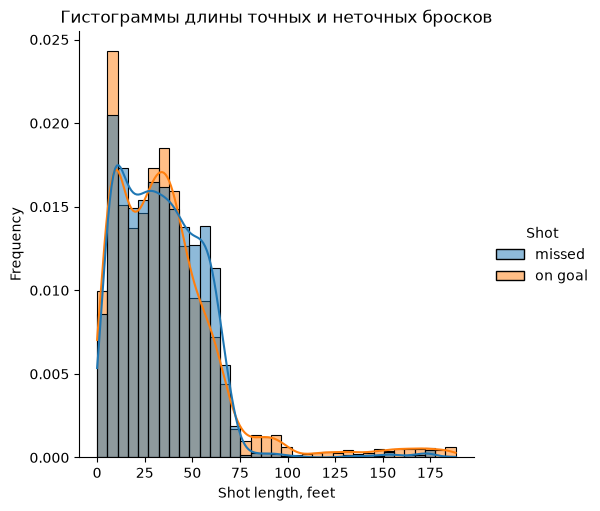

In [73]:
sns.displot(
    data=shot,
    x='Shot Length',
    hue='Shot',
    bins=35,
    stat='density',
    common_norm=False,
    kde=True
)

plt.xlabel('Shot length, feet')
plt.ylabel('Frequency')
plt.title('Гистограммы длины точных и неточных бросков')

plt.show()

In [74]:
shot.groupby('Shot')['Shot Length'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.0,34.01,22.31,0.0,16.16,32.25,49.04,185.07
on goal,4623.0,36.21,30.00,0.0,15.00,31.83,47.01,188.22


9. Сравнение расстояний точных и неточных бросков

Для сравнения точных (`shot-on-goal`, `goal`) и неточных (`missed-shot`) бросков построены нормированные гистограммы с использованием. Нормировка выполнена отдельно для каждой категории, так как количество точных (4623) и неточных(2643) бросков разное.

Распределения имеют схожую форму. Медианное расстояние точных бросков составляет 31,83 фута, неточных — 32,25 фута. По медиане точные броски производятся с немного меньшего расстояния.
Среднее расстояние точных бросков выше: 36,21  vs 34,01 фута. Их стандартное отклонение также выше (30,00 vs 22,31 фута). Длинный правый хвост скорее всего дальние броски из собственной зон
Итого: распределения в центральной части достаточно близки, а различие средних значений связано с редкими дальними бросками

In [78]:
numshots = shot.groupby(
    ['Game ID', 'Team Making the Play', 'Shot']
).size()

numshots.head(10)

Game ID     Team Making the Play  Shot   
2025030111  Boston Bruins         missed     12
                                  on goal    20
            Buffalo Sabres        missed     18
                                  on goal    38
2025030112  Boston Bruins         missed     17
                                  on goal    27
            Buffalo Sabres        missed     20
                                  on goal    35
2025030113  Boston Bruins         missed     11
                                  on goal    25
dtype: int64

In [79]:
numshots=numshots.unstack(fill_value=0)
numshots.head(10)

Shot                             missed  on goal
Game ID    Team Making the Play                 
2025030111 Boston Bruins             12       20
           Buffalo Sabres            18       38
2025030112 Boston Bruins             17       27
           Buffalo Sabres            20       35
2025030113 Boston Bruins             11       25
           Buffalo Sabres            14       30
2025030114 Boston Bruins             16       24
           Buffalo Sabres            19       35
2025030115 Boston Bruins             17       29
           Buffalo Sabres            27       26

In [80]:
numshots['Share of Shots on Goal'] = (
    numshots['on goal'] /
    (numshots['on goal'] + numshots['missed'])
)
numshots.head(10).round(2)

Shot                             missed  on goal  Share of Shots on Goal
Game ID    Team Making the Play                                         
2025030111 Boston Bruins             12       20                    0.62
           Buffalo Sabres            18       38                    0.68
2025030112 Boston Bruins             17       27                    0.61
           Buffalo Sabres            20       35                    0.64
2025030113 Boston Bruins             11       25                    0.69
           Buffalo Sabres            14       30                    0.68
2025030114 Boston Bruins             16       24                    0.60
           Buffalo Sabres            19       35                    0.65
2025030115 Boston Bruins             17       29                    0.63
           Buffalo Sabres            27       26                    0.49

In [82]:
numshots['Share of Shots on Goal'].count()

np.int64(164)

In [83]:
numshots['Share of Shots on Goal'].describe().round(3)

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

Для каждой команды в играх рассчитана доля бросков в створ ворот среди всех незаблокированных бросков. В категорию точных включены броски shot-on-goal и goal, в категорию неточных — missed-shot.
Всего получено 164 наблюдения (82 матча для 2 команд).

Средняя доля точных бросков составила 63,9%, медиана также равна 63,9%.
При этом минимальное значение  35,3%, а максимальное 86,0%. Стандартное отклонение 8,5 пп.
В среднем около 2/3 незаблокированных бросков были в створ ворот. При этом наблюдается заметный разброс доли точных бросков между отдельными наблюдениями.

In [84]:
avgnumshots = numshots.groupby(level='Team Making the Play')['Share of Shots on Goal'].mean()
avgnumshots.round(3)

Team Making the Play
Anaheim Ducks           0.649
Boston Bruins           0.638
Buffalo Sabres          0.626
Carolina Hurricanes     0.615
Colorado Avalanche      0.653
Dallas Stars            0.670
Edmonton Oilers         0.706
Los Angeles Kings       0.642
Minnesota Wild          0.656
Montréal Canadiens      0.644
Ottawa Senators         0.635
Philadelphia Flyers     0.684
Pittsburgh Penguins     0.554
Tampa Bay Lightning     0.626
Utah Mammoth            0.599
Vegas Golden Knights    0.634
Name: Share of Shots on Goal, dtype: float64

In [85]:
avgnumshots.nlargest(5).round(3)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [86]:
avgnumshots.nsmallest(5).round(3)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Наибольшие значения показали Edmonton Oilers (70,6%), Philadelphia Flyers (68,4%) и Dallas Stars (67,0%). 

Самая низкая средняя доля точных бросков наблюдалась у Pittsburgh Penguins (55,4%), Utah Mammoth (59,9%) и Carolina Hurricanes (61,5%).
Между командами есть различия в средней доле бросков в створ ворот: разница между максимальным и минимальным средними показателями в 15,2 пп. 
Но высокая доля точных бросков сама по себе не обязательно означает победу: количество забитых шайб также зависит от общего числа бросков.

In [88]:
team_stats =numshots[['on goal']].copy()
team_stats =team_stats.rename(columns={'on goal': 'Shot'})
goals = shot[shot['Play Type'] =='goal'].groupby(
    ['Game ID', 'Team Making the Play']).size()

team_stats['Goal'] = goals
team_stats['Goal'] = team_stats['Goal'].fillna(0)
team_stats.head(10)

Shot                             Shot  Goal
Game ID    Team Making the Play            
2025030111 Boston Bruins           20   3.0
           Buffalo Sabres          38   4.0
2025030112 Boston Bruins           27   4.0
           Buffalo Sabres          35   2.0
2025030113 Boston Bruins           25   1.0
           Buffalo Sabres          30   3.0
2025030114 Boston Bruins           24   1.0
           Buffalo Sabres          35   6.0
2025030115 Boston Bruins           29   2.0
           Buffalo Sabres          26   1.0

In [92]:
avgshots = team_stats.groupby(
    level='Team Making the Play'
)[['Shot', 'Goal']].mean()
avgshots.round(3)


Shot,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


In [93]:
avgshots.shape

(16, 2)

Для каждой из 16 команд рассчитано среднее количество бросков в створ ворот и забитых шайб за матч. При подсчёте бросков в створ учитывались отражённые броски и голы. Матчи, в которых команда не забила ни одной шайбы, приняты с нулевым значением.

Наибольшее среднее количество бросков в створ наблюдалось у Colorado Avalanche (32,15), Carolina Hurricanes (31,63) и Anaheim Ducks (31,67).

Лидером по среднему количеству голов за матч стала Minnesota Wild (3,73), несмотря на то что команда в среднем наносила 28,73 броска в створ. При этом Colorado Avalanche, имевшая наибольшее среднее число бросков в створ, забивала в среднем 3,38 шайбы.

Таким образом, большее количество бросков в створ не всегда сопровождается большей результативностью

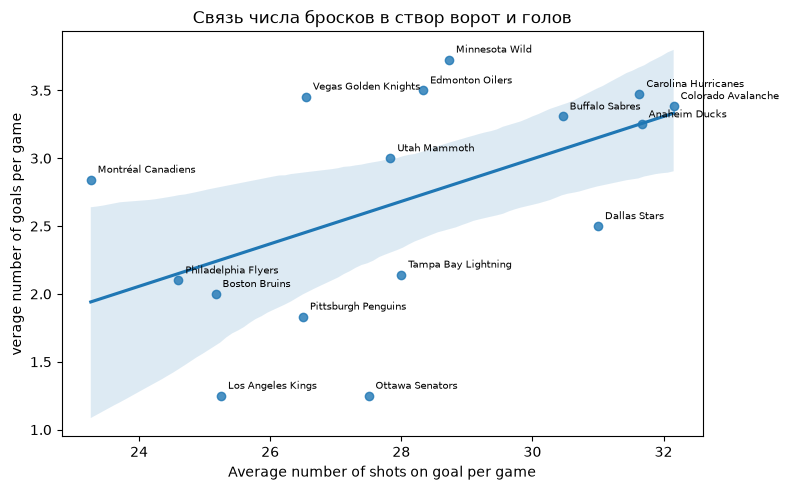

In [99]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=avgshots,
    x='Shot',
    y='Goal'
)
for team in avgshots.index:
    plt.annotate(
        team,
        (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
        fontsize=7,
        xytext=(5, 5),
        textcoords='offset points')

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('verage number of goals per game')
plt.title('Связь числа бросков в створ ворот и голов')

plt.tight_layout()
plt.show()

In [100]:
avgshots['Shot'].corr(avgshots['Goal'])

np.float64(0.5207961205304794)

Линия регрессии имеет положительный наклон, что указывает на наличие положительной связи между показателями. Коэффициент корреляции Пирсона 0,521 говорит об умеренной положительной линейной связи При этом наблюдается значительный разброс точек относительно линии регрессии. 
Таким образом, большее количество бросков в створ в целом связано с большим количеством голов, однако связь не является сильной.

In [101]:
all_shots = events[events['Play Type'].isin([
    'shot-on-goal',
    'goal',
    'missed-shot',
    'blocked-shot'])]

all_shots.shape

(10064, 38)

In [102]:
shots_per_game =all_shots.groupby('Game ID').size()
shots_per_game.sort_values(ascending=False).head(10)

Game ID
2025030132    208
2025030164    169
2025030413    163
2025030126    156
2025030175    154
2025030174    152
2025030152    151
2025030217    151
2025030163    148
2025030115    145
dtype: int64

In [103]:
idxmax = shots_per_game.idxmax()
print(gameInfo(idxmax))
print('Количество бросков:', shots_per_game.max())

Carolina Hurricanes : Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Количество бросков: 208


Для каждого матча подсчитано общее количество бросков по воротам: shot-on-goal, goal, missed-shot и blocked-shot.

Наибольшее количество бросков — 208 — зафиксировано в матче Carolina Hurricanes — Ottawa Senators (3:2). 

In [104]:
match_shots =all_shots[all_shots['Game ID'] ==idxmax].copy()
match_shots.shape

(208, 38)

In [105]:
match_shots[[
    'Period',
    'Team Making the Play',
    'Play Type',
    'X Coordinate on the Ice Rink',
    'Y Coordinate on the Ice Rink',
    "Home Team's Defending Side"
]].head(10)

,Period,Team Making the Play,Play Type,X Coordinate on the Ice Rink,Y Coordinate on the Ice Rink,Home Team's Defending Side
5057,1,Carolina Hurricanes,shot-on-goal,-63.0,-15.0,right
5061,1,Ottawa Senators,missed-shot,87.0,-7.0,right
5063,1,Carolina Hurricanes,shot-on-goal,-66.0,12.0,right
5068,1,Ottawa Senators,blocked-shot,66.0,21.0,right
5069,1,Carolina Hurricanes,blocked-shot,-64.0,-33.0,right
5070,1,Ottawa Senators,missed-shot,48.0,29.0,right
5072,1,Ottawa Senators,missed-shot,32.0,27.0,right
5073,1,Ottawa Senators,shot-on-goal,76.0,-24.0,right
5074,1,Ottawa Senators,blocked-shot,89.0,0.0,right
5078,1,Carolina Hurricanes,shot-on-goal,-68.0,-39.0,right


In [108]:
match_shots.groupby(
    ['Period', "Home Team's Defending Side"]).size()

Period  Home Team's Defending Side
1       right                         46
2       left                          45
3       right                         40
4       left                          42
5       right                         35
dtype: int64

In [109]:
match_shots['Plot X'] = match_shots['X Coordinate on the Ice Rink']
match_shots['Plot Y']= match_shots['Y Coordinate on the Ice Rink']
odd = match_shots['Period'] % 2 == 1
match_shots.loc[odd, 'Plot X']= -match_shots.loc[odd, 'Plot X']
match_shots.loc[odd, 'Plot Y']= -match_shots.loc[odd, 'Plot Y']

In [110]:
match_shots[[
    'Period',
    'Team Making the Play',
    'Plot X',
    'Plot Y']].head(10)

,Period,Team Making the Play,Plot X,Plot Y
5057,1,Carolina Hurricanes,63.0,15.0
5061,1,Ottawa Senators,-87.0,7.0
5063,1,Carolina Hurricanes,66.0,-12.0
5068,1,Ottawa Senators,-66.0,-21.0
5069,1,Carolina Hurricanes,64.0,33.0
5070,1,Ottawa Senators,-48.0,-29.0
5072,1,Ottawa Senators,-32.0,-27.0
5073,1,Ottawa Senators,-76.0,24.0
5074,1,Ottawa Senators,-89.0,-0.0
5078,1,Carolina Hurricanes,68.0,39.0


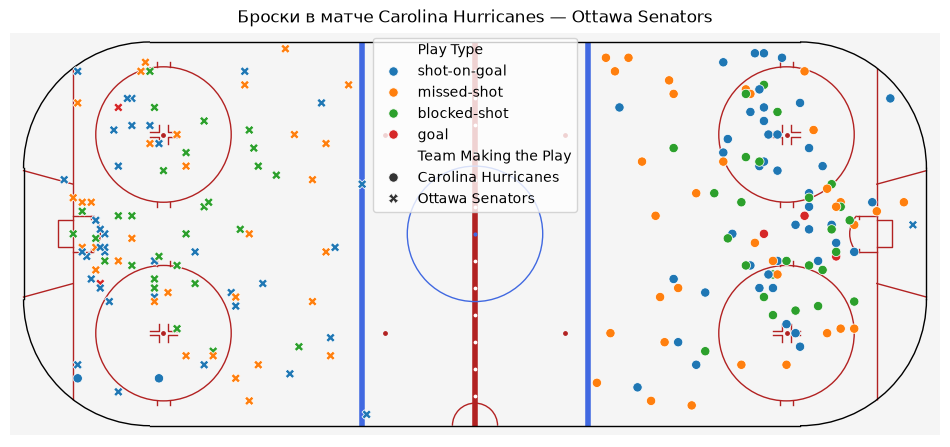

In [111]:
from rink import plot_rink

plt.figure(figsize=(12, 6))
plot_rink()

sns.scatterplot(
    data=match_shots,
    x='Plot X',
    y='Plot Y',
    hue='Play Type',
    style='Team Making the Play',
    s=45
)

plt.gca().set_aspect('equal')
plt.xlim(-103, 103)
plt.ylim(-45, 45)

plt.title('Броски в матче Carolina Hurricanes — Ottawa Senators')
plt.axis('off')

plt.show()

In [112]:
goals_only = events[events['Play Type'] =='goal'].copy()
goals_only.shape

(486, 38)

In [113]:
top_goal_scorers = goals_only['Player in the Event #1'].value_counts()
top_goal_scorers.head(10)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64

Для событий типа goal был использован столбец Player in the Event #1 с фамилией игрока, забившего шайбу. По каждому игроку подсчитано общее число голов за все матчи, после чего сформирован список десяти лучших 

In [114]:
a = pd.concat([
    goals_only['Player in the Event #2'],
    goals_only['Player in the Event #3']
])
a.head(10)

80       David Pastrnak
262       Morgan Geekie
321        Peyton Krebs
344           Alex Tuch
356          Jack Quinn
364       Tage Thompson
372         Pavel Zacha
526    Jonathan Aspirot
587      David Pastrnak
608      David Pastrnak
dtype: str

In [115]:
a= a.dropna()

In [116]:
top = a.value_counts()
top.head(10)

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

In [117]:
print('Всего голевых передач:', len(a))
print('Игроков с передачами:', a.nunique())

Всего голевых передач: 830
Игроков с передачами: 231


Для определения лучших игроков, передающих пас, были объединены данные из столбцов Player in the Event #2 и Player in the Event #3 для событий типа goal. После удаления пропущенных значений подсчитано количество голевых передач каждого игрока.
Всего зарегистрировано 830 голевых передач, которые совершил 231 игрок.
Лидером по количеству передач стал Jack Eichel (20), второе место занял Mitch Marner (19).

In [119]:
points = pd.concat([
    goals_only['Player in the Event #1'].value_counts(),
    a.value_counts()], axis=1)
points.columns = ['Goals', 'Assists']
points =points.fillna(0).astype(int)
points.head(10)

,Goals,Assists
Brett Howden,14,4
Pavel Dorofeyev,12,4
Logan Stankoven,11,5
Mitch Marner,10,19
Nikolaj Ehlers,8,10
Jordan Staal,8,4
Alex Newhook,7,3
Taylor Hall,7,12
Jackson Blake,7,13
Nathan MacKinnon,7,8


In [120]:
points['Points']= points['Goals']+points['Assists']
points.sort_values('Points', ascending=False).head(10)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Nikolaj Ehlers,8,10,18
Brett Howden,14,4,18
Shea Theodore,6,12,18
Logan Stankoven,11,5,16
Lane Hutson,3,13,16
Nick Suzuki,4,12,16


для каждого игрока рассчитано общее количество очков -это сумма голов и голевых передач. При объединении таблиц отсутствующие значения заменены нулями.

Лидером по суммарной результативности стал Mitch Marner, набравший 29 очков (10 голов и 19 передач). 
При этом лучший снайпер Brett Howden с 14 голами набрал 18 очков и занял шестое место по суммарной результативности.

Таким образом, рейтинг по системе «гол + пас» отличается от рейтинга снайперов

In [121]:
player_shots = events[
    events['Play Type'].isin(['shot-on-goal', 'goal'])
]
shots_count = player_shots['Player in the Event #1'].value_counts()
shots_count.head(10)

Player in the Event #1
Pavel Dorofeyev      58
Mitch Marner         57
Taylor Hall          55
Logan Stankoven      55
Andrei Svechnikov    53
Jack Eichel          52
Juraj SlafkovskÃ½    48
Matt Boldy           48
Seth Jarvis          47
Nathan MacKinnon     47
Name: count, dtype: int64

In [122]:
players_on_ice = events.set_index('Game ID')[away + home].stack().reset_index()
players_on_ice.columns = ['Game ID', 'Position', 'Player']
players_on_ice.head(10)

,Game ID,Position,Player
0,2025030111,Away Team's Player on the Ice #1,Viktor Arvidsson
1,2025030111,Away Team's Player on the Ice #2,Jonathan Aspirot
2,2025030111,Away Team's Player on the Ice #3,Charlie McAvoy
3,2025030111,Away Team's Player on the Ice #4,Casey Mittelstadt
4,2025030111,Away Team's Player on the Ice #5,Jeremy Swayman
5,2025030111,Away Team's Player on the Ice #6,Pavel Zacha
6,2025030111,Away Team's Goalie,Jeremy Swayman
7,2025030111,Home Team's Player on the Ice #1,Rasmus Dahlin
8,2025030111,Home Team's Player on the Ice #2,Peyton Krebs
9,2025030111,Home Team's Player on the Ice #3,Ukko-Pekka Luukkonen


In [123]:
games_played = players_on_ice.groupby('Player')['Game ID'].nunique()
games_played.head(10)

Player
Adam Erne           1
Adam Henrique       1
Adrian Kempe        4
Alex Bump           6
Alex Killorn       12
Alex Laferriere     4
Alex Lyon          10
Alex Newhook       19
Alex Steeves        2
Alex Tuch          13
Name: Game ID, dtype: int64

In [125]:
player_stats = pd.DataFrame({
    'Shots': shots_count,
    'Games': games_played})

player_stats = player_stats.fillna(0)
player_stats.head(10)

,Shots,Games
Adam Erne,2.0,1
Adam Henrique,1.0,1
Adrian Kempe,5.0,4
Alex Bump,10.0,6
Alex Killorn,25.0,12
Alex Laferriere,15.0,4
Alex Lyon,0.0,10
Alex Newhook,34.0,19
Alex Steeves,3.0,2
Alex Tuch,46.0,13


In [126]:
player_stats['Shots per Game'] = (
    player_stats['Shots'] / player_stats['Games'])
player_stats.sort_values(
    'Shots per Game', ascending=False).head(10).round(3)

,Shots,Games,Shots per Game
Jason Robertson,30.0,6,5.000
Dylan Guenther,27.0,6,4.500
Nikita Kucherov,31.0,7,4.429
Matt Boldy,48.0,11,4.364
Quinton Byfield,17.0,4,4.250
Darren Raddysh,28.0,7,4.000
Joel Eriksson Ek,24.0,6,4.000
Alex Laferriere,15.0,4,3.750
David Pastrnak,22.0,6,3.667
Nathan MacKinnon,47.0,13,3.615


Рейтинг по среднему количеству бросков за матч позволяет сопоставлять активность игроков с разным количеством сыгранных матчей.
Для этого для каждого игрока подсчитано общее количество бросков в створ ворот (shot-on-goal и goal) и число матчей, в которых он участвовал. При подсчёте матчей учитывались и игры без бросков в створ.
Среднее количество бросков рассчитано как отношение общего числа бросков в створ к количеству сыгранных матчей.
Лидером стал Jason Robertson со средним показателем 5,00 бросков за матч. 

In [127]:
hits =events[events['Play Type'] == 'hit']
hits_count = hits['Player in the Event #1'].value_counts()
hits_count.head(10)

Player in the Event #1
Ivan Barbashev       110
Cole Smith           100
William Carrier       91
Jordan Staal          86
Keegan Kolesar        82
Andrei Svechnikov     74
Sean Walker           68
Colton Sissons        67
Brett Howden          64
Nic Dowd              61
Name: count, dtype: int64

In [128]:
hit_stats = pd.DataFrame({
    'Hits': hits_count,
    'Games': games_played})

hit_stats = hit_stats.fillna(0)
hit_stats.head(10)

,Hits,Games
Adam Erne,2.0,1
Adam Henrique,1.0,1
Adrian Kempe,6.0,4
Alex Bump,9.0,6
Alex Killorn,14.0,12
Alex Laferriere,18.0,4
Alex Lyon,0.0,10
Alex Newhook,31.0,19
Alex Steeves,7.0,2
Alex Tuch,37.0,13


In [130]:
hit_stats['Hits per Game'] =(
    hit_stats['Hits'] / hit_stats['Games'])

hit_stats.sort_values(
    'Hits per Game', ascending=False).head(10).round(3)

,Hits,Games,Hits per Game
Lawson Crouse,38.0,6,6.333
Alexander Petrovic,6.0,1,6.000
Alex Turcotte,6.0,1,6.000
Yakov Trenin,51.0,9,5.667
Dylan Cozens,22.0,4,5.500
Vasily Podkolzin,32.0,6,5.333
Carl Grundstrom,15.0,3,5.000
Ivan Barbashev,110.0,22,5.000
Marcus Foligno,55.0,11,5.000
Owen Tippett,29.0,6,4.833


Для каждого игрока подсчитано общее количество силовых приёмов на основе hit и столбца Player in the Event #1. Затем полученные значения разделены на количество матчей, в которых игрок участвовал.
Лидером по среднему количеству силовых приёмов стал Lawson Crouse — 6,33 за матч (38 приёмов за 6 игр). Следом идут Alexander Petrovic и Alex Turcotte — по 6 приёмов за матч, однако каждый из них участвовал только в одной игре.


In [131]:
events[[
    'Game ID',
    'Away Team',
    'Home Team',
    "Away Team's Goalie",
    "Home Team's Goalie"
]].head(10)

,Game ID,Away Team,Home Team,Away Team's Goalie,Home Team's Goalie
0,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
1,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
2,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
3,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
4,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
5,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
6,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
7,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
8,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
9,2025030111,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen


In [133]:
goal_events = events[events['Play Type'] == 'goal']
goal_events[[
    'Game ID',
    'Team Making the Play',
    'Away Team',
    'Home Team',
    "Away Team's Goalie",
    "Home Team's Goalie"
]].head(10)

,Game ID,Team Making the Play,Away Team,Home Team,Away Team's Goalie,Home Team's Goalie
80,2025030111,Boston Bruins,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
262,2025030111,Boston Bruins,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
321,2025030111,Buffalo Sabres,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
344,2025030111,Buffalo Sabres,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
356,2025030111,Buffalo Sabres,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
364,2025030111,Buffalo Sabres,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
372,2025030111,Boston Bruins,Boston Bruins,Buffalo Sabres,NaN,Ukko-Pekka Luukkonen
526,2025030112,Boston Bruins,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
587,2025030112,Boston Bruins,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen
608,2025030112,Boston Bruins,Boston Bruins,Buffalo Sabres,Jeremy Swayman,Ukko-Pekka Luukkonen


In [134]:
away_goalies = events[['Game ID', "Away Team's Goalie"]].copy()
away_goalies.columns = ['Game ID', 'Goalie']
home_goalies = events[['Game ID', "Home Team's Goalie"]].copy()
home_goalies.columns = ['Game ID', 'Goalie']
goalie_games = pd.concat([away_goalies, home_goalies])
goalie_games = goalie_games.dropna().drop_duplicates()
goalie_games.head(10)

,Game ID,Goalie
0,2025030111,Jeremy Swayman
376,2025030112,Jeremy Swayman
777,2025030113,Alex Lyon
1105,2025030114,Alex Lyon
1464,2025030115,Jeremy Swayman
1856,2025030116,Alex Lyon
2200,2025030121,Jakub Dobes
2551,2025030122,Jakub Dobes
2980,2025030123,Andrei Vasilevskiy
3299,2025030124,Andrei Vasilevskiy


In [136]:
home_conceded = goal_events[
    goal_events['Team Making the Play'] == goal_events['Away Team']
][['Game ID', "Home Team's Goalie"]].copy()
home_conceded.columns = ['Game ID', 'Goalie']

away_conceded = goal_events[
    goal_events['Team Making the Play'] == goal_events['Home Team']
][['Game ID', "Away Team's Goalie"]].copy()
away_conceded.columns = ['Game ID', 'Goalie']

conceded = pd.concat([home_conceded, away_conceded]).dropna()
goals_against = conceded.groupby(
    ['Game ID', 'Goalie']
).size().reset_index(name='Goals Against')

goals_against.head(10)

,Game ID,Goalie,Goals Against
0,2025030111,Jeremy Swayman,4
1,2025030111,Ukko-Pekka Luukkonen,3
2,2025030112,Alex Lyon,1
3,2025030112,Jeremy Swayman,2
4,2025030112,Ukko-Pekka Luukkonen,3
5,2025030113,Alex Lyon,1
6,2025030113,Jeremy Swayman,3
7,2025030114,Alex Lyon,1
8,2025030114,Jeremy Swayman,6
9,2025030115,Alex Lyon,1


In [137]:
goalie_stats = goalie_games.merge(
    goals_against,
    on=['Game ID', 'Goalie'],
    how='left'
)

goalie_stats['Goals Against'] = goalie_stats['Goals Against'].fillna(0)
goalie_stats.head(10)

,Game ID,Goalie,Goals Against
0,2025030111,Jeremy Swayman,4.0
1,2025030112,Jeremy Swayman,2.0
2,2025030113,Alex Lyon,1.0
3,2025030114,Alex Lyon,1.0
4,2025030115,Jeremy Swayman,1.0
5,2025030116,Alex Lyon,1.0
6,2025030121,Jakub Dobes,3.0
7,2025030122,Jakub Dobes,2.0
8,2025030123,Andrei Vasilevskiy,2.0
9,2025030124,Andrei Vasilevskiy,2.0


In [138]:
zero_goal = goalie_stats[
    goalie_stats['Goals Against'] == 0
]

zero_goal[['Game ID', 'Goalie']].sort_values('Goalie')
sorted(zero_goal['Goalie'].unique())

['Andrei Vasilevskiy',
 'Arturs Silovs',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Jakub Dobes',
 'Joonas Korpisalo',
 'Scott Wedgewood']

Для каждого матча определены все вратари, находившиеся на льду за игру (основные и  на замене) На основе goal подсчитано количество шайб, пропущенных каждым вратарём. Голы, забитые в пустые ворота, не приписывались отсутствующему вратарю.
После объединения данных об участии вратарей и пропущенных шайбах определены вратари, которые хотя бы в одном матче не пропустили ни одного гола.

Всего найдено 8 таких вратарей: Andrei Vasilevskiy, Arturs Silovs, Brandon Bussi, Dan Vladar, Frederik Andersen, Jakub Dobes, Joonas Korpisalo и Scott Wedgewood.

22. существует ли преимущество домашней площадки?

Сравним как команды, играющие на домашней площадке, побеждают, забивают и совершают больше бросков в створ ворот по сравнению с гостевыми командами

In [139]:
games['Home Win'] = games['Home Score'] > games['Away Score']
games[['Home Team', 'Away Team', 'Home Score',
       'Away Score', 'Home Win']].head(10)
home_wins = games['Home Win'].sum()
away_wins = len(games) - home_wins

print('Побед хозяев:', home_wins)
print('Побед гостей:', away_wins)

Побед хозяев: 39
Побед гостей: 43


In [140]:
home_win_share = home_wins / len(games)
print('Доля побед хозяев:', round(home_win_share * 100, 2), '%')
print('Доля побед гостей:', round((1 - home_win_share) * 100, 2), '%')

Доля побед хозяев: 47.56 %
Доля побед гостей: 52.44 %


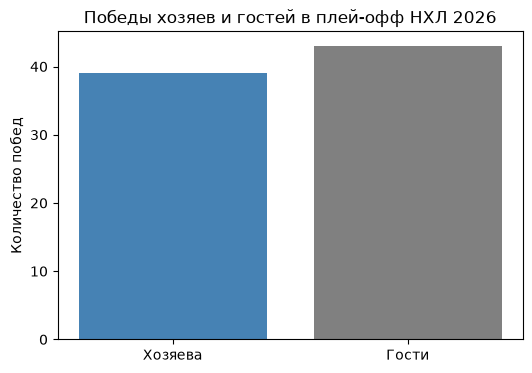

In [151]:
plt.figure(figsize=(6, 4))

plt.bar(
    ['Хозяева', 'Гости'],
    [home_wins, away_wins],
    color=['steelblue', 'gray']
)

plt.ylabel('Количество побед')
plt.title('Победы хозяев и гостей в плей-офф НХЛ 2026')
plt.show()

в данной выборке преимущество домашней площадки по частоте побед не наблюдается.

In [143]:
games[['Home Score', 'Away Score']].mean().round(3)

Home Score    2.805
Away Score    3.122
dtype: float64

In [144]:
games[['Home Score', 'Away Score']].sum()

Home Score    230
Away Score    256
dtype: int64

За 82 матча команды хозяев забили 230 шайб, а гостевые команды — 256 шайб.
Средняя результативность хозяев составила 2,81 шайбы за матч, гостей — 3,12 шайбы. Таким образом, гости в среднем забивали на 0,32 шайбы больше.
Полученные результаты согласуются с небольшим преимуществом гостей по доле побед (52,44% против 47,56%). (вопрос о статистической значимости открыт)

In [145]:
shots_venue = numshots[['on goal']].reset_index()
shots_venue = shots_venue.merge(
    games[['Home Team']],
    left_on='Game ID',
    right_index=True
)
shots_venue.head()

,Game ID,Team Making the Play,on goal,Home Team
0,2025030111,Boston Bruins,20,Buffalo Sabres
1,2025030111,Buffalo Sabres,38,Buffalo Sabres
2,2025030112,Boston Bruins,27,Buffalo Sabres
3,2025030112,Buffalo Sabres,35,Buffalo Sabres
4,2025030113,Boston Bruins,25,Boston Bruins


In [147]:
shots_venue['Venue'] = 'Away'
shots_venue.loc[
    shots_venue['Team Making the Play'] == shots_venue['Home Team'],
    'Venue'
] = 'Home'
shots_venue.groupby('Venue')['on goal'].agg(
    ['count', 'sum', 'mean']
).round(3)

,count,sum,mean
Venue,,,
Away,82,2299,28.037
Home,82,2324,28.341


Хозяева немного чаще бросали в створ ворот, но гости при этом забивали больше голов и чаще побеждали. возможно, гости эффективнее реализовывали свои броски

In [148]:
home_conversion = games['Home Score'].sum() / 2324 * 100
away_conversion = games['Away Score'].sum() / 2299 * 100
print('Реализация хозяев:', round(home_conversion, 2), '%')
print('Реализация гостей:', round(away_conversion, 2), '%')

Реализация хозяев: 9.9 %
Реализация гостей: 11.14 %


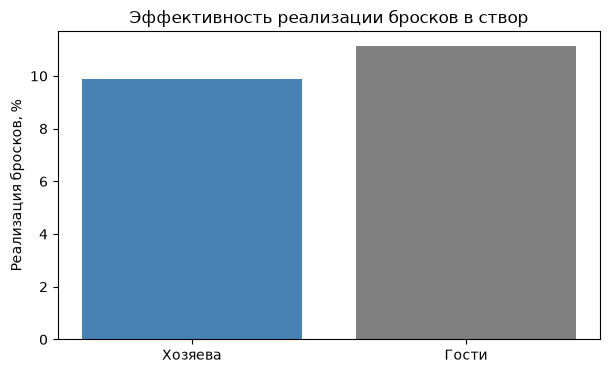

In [150]:
plt.figure(figsize=(7, 4))

plt.bar(
    ['Хозяева', 'Гости'],
    [home_conversion, away_conversion],
    color=['steelblue', 'gray']
)

plt.ylabel('Реализация бросков, %')
plt.title('Эффективность реализации бросков в створ')

plt.show()

Проверка  гипотезы: p — вероятность победы хозяев

H0: p=0.5 (хозяева и гости имеют одинаковую вероятность победить)
H1: p!= 0.5

In [149]:
from scipy.stats import binomtest

test = binomtest(
    k=home_wins,
    n=len(games),
    p=0.5
)
print('p-value:', round(test.pvalue, 4))

p-value: 0.7407


При уровне значимости a=0.05 не отвергаем нулевую гипотезу - наблюдаемая разница между 39 и 43 победами статистически незначима

проверили, имеют ли команды, выступающие на домашней площадке, преимущество по частоте побед, результативности и количеству бросков в створ ворот.

1. Частота побед. Из 82 матчей хозяева выиграли 39 (47,56%), гости — 43 (52,44%). Таким образом, в рассматриваемой выборке гости побеждали немного чаще.

Для проверки статистической значимости различий проведён двусторонний биномиальный тест с нулевой гипотезой о равной вероятности победы хозяев и гостей. Получено p-value = 0,7407. На уровне значимости 5% нулевая гипотеза не отвергается. Следовательно, статистически значимого преимущества одной из сторон по частоте побед не обнаружено.

2. Результативность. Гости в среднем забивали 3,12 шайбы за матч против 2,81 у хозяев. За всю серию игр гости забили 256 шайб, хозяева — 230.

3. Количество бросков. Хозяева совершали в среднем 28,34 броска в створ ворот за матч, гости 28,04. Таким образом, несмотря на небольшое преимущество хозяев по количеству бросков, гости продемонстрировали более высокую результативность.

4. Эффективность реализации. Доля бросков в створ, завершившихся голом, составила около 9,90% у хозяев и 11,14% у гостей. Это позволяет предположить, что более высокая результативность гостей связана с большей эффективностью реализации бросков.

По результатам анализа 82 матчей не обнаружено статистически значимого преимущества домашней площадки по вероятности победы. Более того, в рассматриваемой выборке гости немного чаще побеждали и забивали больше шайб, несмотря на несколько меньшее количество бросков в створ